# Placement survival lab

A walkthrough of the mock-data pipeline behind the thriving and retention approach:

1. simulate agency placements where the truth is known,
2. turn them into one row per placement per month and fit a discrete-time competing-risks model,
3. check it recovers the truth despite censoring,
4. validate it the honest way (train on older placements, test on newer),
5. measure what the day-30 and day-90 check-ins add,
6. replay the same pipeline on two public turnover datasets.

The last cell writes every result into [dashboard.html](dashboard.html). Background and sources: [DATA_AND_CHECKINS.md](../DATA_AND_CHECKINS.md). Runs in about 15 seconds.

In [3]:
import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import pipeline as pp
import replay
import sim

# Validated categorical palette (fixed order, never cycled) + chart chrome
S = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
INK, MUTED, GRID = "#0f1720", "#7d8591", "#e3e7ec"
plt.rcParams.update({
    "figure.figsize": (7.5, 3.4), "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED, "lines.linewidth": 2,
    "legend.frameon": False, "font.size": 9.5,
})
pd.set_option("display.precision", 3)
MONTHS = np.arange(1, pp.MAX_M + 1)
R = {}  # everything the dashboard shows

## 1. Simulate 5,000 placements

Hidden variables drive both exits and check-in answers: candidate fit, site-manager quality and supervisor undermining. The model only ever sees `pl` and `ci`. `truth` holds the hidden and uncensored values for the checks.

In [5]:
pl, ci, truth = sim.simulate(n=5000, seed=7)
df = pp.from_ats(pl, sim.SNAPSHOT)
df["mgr_hist"] = pp.manager_history(df)   # manager's earlier early-exit rate, no peeking
CATS = ["occupation", "emp_type", "source"]
NUMS = ["tenure_norm_z", "relevance_z", "pay_uplift_pct", "screen_z", "mgr_hist"]
display(pl.head())
pl.exit_reason.fillna("still there").value_counts().rename("placements").to_frame()

,placement_id,client_id,manager_id,occupation,emp_type,source,start_date,tenure_norm_z,relevance_z,pay_uplift_pct,screen_z,referral,end_date,exit_reason,days_guaranteed
0,1,53,130,plumber,temp,database,2021-10-01,0.41,-0.17,-3.6,0.85,0,2021-12-09,quit,0
1,2,131,365,site_admin,perm,job_board,2021-10-01,-2.12,0.68,26.1,0.23,0,NaT,NaN,90
2,3,3,193,plant_operator,temp,job_board,2021-10-01,0.13,-0.58,10.3,0.15,0,2023-09-20,converted,0
3,4,51,211,electrician,perm,database,2021-10-02,-1.25,-1.17,-14.7,0.74,0,2021-10-26,quit,90
4,5,112,440,labourer,temp,database,2021-10-02,-0.60,0.73,10.4,-0.75,0,2022-01-01,contract_end,0


,placements
exit_reason,
still there,1766
quit,1426
contract_end,1168
converted,487
dismissed,153


In [6]:
perm = (df.emp_type == "perm").to_numpy()
tr = truth[perm]
bad_true = tr.true_cause.isin(pp.BAD).to_numpy()
true_curve = np.array([(bad_true & (tr.true_end_months <= t)).mean() for t in MONTHS])
targets = {3: 0.12, 12: 0.27, 24: 0.38}  # ELMO probation leavers, new-nurse cohort, trades assumption

R["meta"] = dict(
    n=len(pl), n_perm=int(perm.sum()), n_temp=int((~perm).sum()),
    n_clients=int(pl.client_id.nunique()), n_managers=int(pl.manager_id.nunique()),
    first_start=f"{pl.start_date.min():%b %Y}", snapshot=f"{sim.SNAPSHOT:%d %b %Y}",
    exits=pl.exit_reason.fillna("still there").value_counts().to_dict(),
    targets={str(k): v for k, v in targets.items()},
    true_at={str(t): float(true_curve[t - 1]) for t in (3, 6, 12, 18, 24)},
)
pd.DataFrame({"true P(quit or dismissed by t), perm": true_curve[[t - 1 for t in targets]],
              "target": list(targets.values())}, index=[f"{t} months" for t in targets])

,"true P(quit or dismissed by t), perm",target
3 months,0.118,0.12
12 months,0.280,0.27
24 months,0.379,0.38


## 2. What the model sees: one row per placement per month

Each placement becomes one row per month at risk, up to month 24. `y` is the exit type in the month it happened (1 = quit, 2 = dismissed, 3 = converted), otherwise 0. A multinomial logistic regression on these rows is a discrete-time hazard model. Multiplying the monthly stay-probabilities gives survival at every horizon, so the 6, 12, 18 and 24-month answers can never contradict each other.

In [7]:
pm = pp.person_month(df.iloc[:2])
pm.groupby("placement_id").tail(3)[["placement_id", "occupation", "emp_type", "month", "y"]]

,placement_id,occupation,emp_type,month,y
0,1,plumber,temp,1,0
1,1,plumber,temp,2,0
2,1,plumber,temp,3,1
24,2,site_admin,perm,22,0
25,2,site_admin,perm,23,0
26,2,site_admin,perm,24,0


## 3. Check: does it recover the truth despite censoring?

Fit on the censored data we would really hold on 30 Sep 2026, then compare with the true, uncensored outcomes. The two shortcuts a plain "left by month X?" classifier forces on you are shown for contrast.

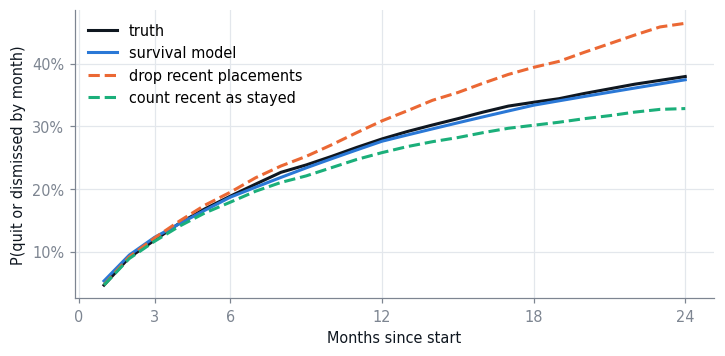

,truth,survival model,drop recent placements,count recent as stayed
6,0.189,0.187,0.195,0.179
12,0.280,0.276,0.309,0.258
18,0.338,0.334,0.394,0.302
24,0.379,0.374,0.464,0.328


In [8]:
full = pp.HazardModel(CATS, NUMS).fit(df)
r_perm = full.risk(df[perm])
assert (np.diff(r_perm, axis=1) >= -1e-12).all(), "curves must be monotone"

d = df[perm]
drop, stayed = [], []
for t in MONTHS:
    y = (d.cause.isin(pp.BAD) & (d.duration <= t)).to_numpy()
    known = ((d.duration > t) | (d.cause != 0)).to_numpy()
    drop.append(y[known].mean())
    stayed.append(y.mean())
rec = pd.DataFrame({"truth": true_curve, "survival model": r_perm.mean(0),
                    "drop recent placements": drop, "count recent as stayed": stayed}, index=MONTHS)
for t in pp.HORIZONS:
    assert abs(rec.loc[t, "survival model"] - rec.loc[t, "truth"]) < 0.02, t

ax = rec.plot(color=[INK, S[0], S[1], S[2]], style=["-", "-", "--", "--"])
ax.set(xlabel="Months since start", ylabel="P(quit or dismissed by month)", xticks=[0, 3, 6, 12, 18, 24])
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
plt.show()

R["recovery"] = {"months": MONTHS.tolist(), **{k: rec[k].round(4).tolist() for k in rec}}
rec.loc[list(pp.HORIZONS)]

## 4. Retention by segment

Model estimate of P(still there), meaning no quit or dismissal, averaged over each segment. A planned contract end or a temp-to-perm conversion is not a bad exit.

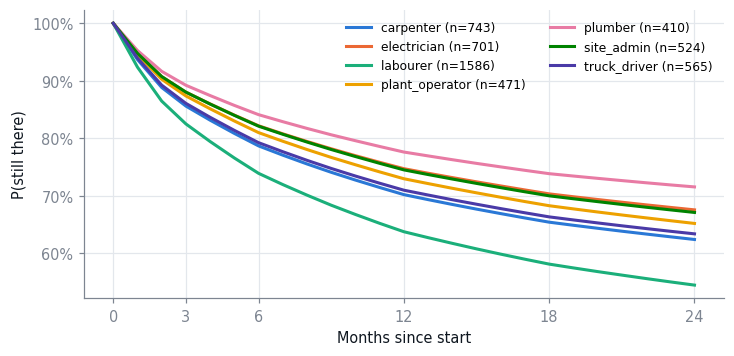

In [9]:
still = 1 - full.risk(df)
R["segments"] = {
    dim: {lvl: {"n": int((df[dim] == lvl).sum()),
                "curve": [1.0] + still[(df[dim] == lvl).to_numpy()].mean(0).round(4).tolist()}
          for lvl in sorted(df[dim].unique())}
    for dim in ["occupation", "source", "emp_type"]
}
fig, ax = plt.subplots()
for i, (lvl, v) in enumerate(R["segments"]["occupation"].items()):
    ax.plot(range(25), v["curve"], color=S[i], label=f"{lvl} (n={v['n']})")
ax.set(xlabel="Months since start", ylabel="P(still there)", xticks=[0, 3, 6, 12, 18, 24])
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.legend(fontsize=8, ncol=2)
plt.show()

## 5. Honest validation: train on older placements, test on newer ones

IPCW metrics at each horizon: AUC (ranking), Brier score (accuracy of the probability) and calibration (predicted vs observed). A horizon is only judged when at least 30 test placements have been observed that long.

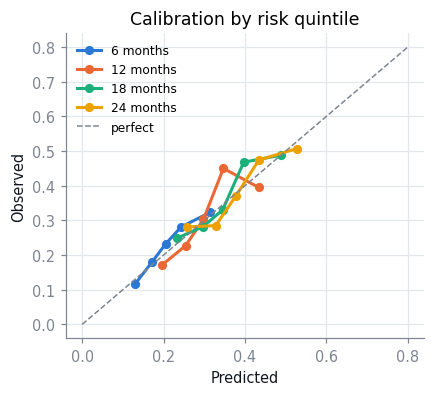

,n_beyond,auc,brier,predicted,observed
6,959,0.63,0.165,0.213,0.219
12,483,0.639,0.198,0.306,0.294
18,240,0.617,0.221,0.352,0.354
24,73,0.607,0.229,0.385,0.379


In [10]:
CUT = pd.Timestamp("2024-07-01")
train, test = df[df.start_date < CUT], df[df.start_date >= CUT]
static = pp.HazardModel(CATS, NUMS).fit(train)
r_test = static.risk(test)
val = {t: pp.evaluate(test.duration, test.cause, r_test[:, t - 1], t) for t in pp.HORIZONS}
R["validation"] = {"cut": f"{CUT:%b %Y}", "n_train": len(train), "n_test": len(test),
                   "horizons": {str(t): v for t, v in val.items()}}

fig, ax = plt.subplots(figsize=(4.2, 3.6))
for i, (t, m) in enumerate(val.items()):
    if m:
        p, o = zip(*m["calib_by_quintile"])
        ax.plot(p, o, "o-", color=S[i], label=f"{t} months", markersize=5)
ax.plot([0, 0.8], [0, 0.8], "--", color=MUTED, lw=1, label="perfect")
ax.set(xlabel="Predicted", ylabel="Observed", title="Calibration by risk quintile")
ax.legend(fontsize=8)
plt.show()
pd.DataFrame(val).T[["n_beyond", "auc", "brier", "predicted", "observed"]]

## 6. What the check-ins add

First the raw signal: how many placements were gone within 6 months, by their day-30 answer to "How likely are you to be looking for a different job in the next 3 months?". Then the model: for placements still there at month 4, does adding the day-30 and day-90 answers sharpen the prediction?

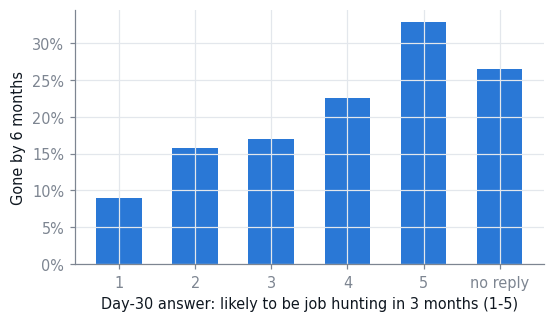

,n,share
answer,,
1,413,0.090
2,643,0.157
3,768,0.169
4,586,0.225
5,387,0.328
no reply,617,0.264


,static,checkins,n_beyond
6,0.615,0.668,959.0
12,0.613,0.676,483.0
18,0.591,0.672,240.0
24,0.589,0.665,73.0


In [11]:
c30 = ci[ci.day == 30].merge(df[["placement_id", "duration", "cause"]], on="placement_id")
c30 = c30[(c30.duration > 6) | (c30.cause != 0)].copy()          # outcome at 6 months is known
c30["gone_by_6m"] = c30.cause.isin(pp.BAD) & (c30.duration <= 6)
c30["answer"] = np.where(c30.responded == 1, c30.quit_intent.fillna(0).astype(int).astype(str), "no reply")
by_answer = c30.groupby("answer").gone_by_6m.agg(n="size", share="mean").reindex(["1", "2", "3", "4", "5", "no reply"])
undermine = c30[c30.responded == 1].groupby("undermining").gone_by_6m.agg(n="size", share="mean")

live = test[test.duration > 3]
with_ci = pp.HazardModel(CATS, NUMS, checkins=ci).fit(train)
r0, r1 = static.risk(live, from_month=4), with_ci.risk(live, from_month=4)
lift = {}
for t in pp.HORIZONS:
    a, b = (pp.evaluate(live.duration, live.cause, r[:, t - 4], t) for r in (r0, r1))
    if a and b:
        lift[str(t)] = {"static": a["auc"], "checkins": b["auc"], "n_beyond": a["n_beyond"]}
assert lift["12"]["checkins"] > lift["12"]["static"]

R["checkins"] = {
    "by_answer": [{"answer": k, "n": int(v.n), "share": round(float(v.share), 4)} for k, v in by_answer.iterrows()],
    "undermining": {("yes" if k == 1 else "no"): {"n": int(v.n), "share": round(float(v.share), 4)}
                    for k, v in undermine.iterrows()},
    "lift": lift, "n_live": len(live),
}
fig, ax = plt.subplots(figsize=(5.5, 3))
ax.bar(by_answer.index, by_answer.share, color=S[0], width=0.6)
ax.set(xlabel="Day-30 answer: likely to be job hunting in 3 months (1-5)", ylabel="Gone by 6 months")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
plt.show()
display(by_answer)
pd.DataFrame(lift).T

## 7. Placement explorer

150 test placements still there at month 4, each with its curve at placement, its curve after the day-90 check-in, its answers and what actually happened. These feed the explorer panel in the dashboard.

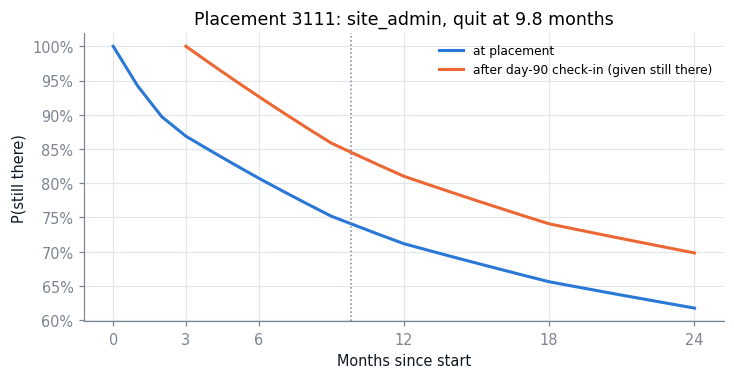

In [12]:
rng = np.random.default_rng(3)
idx = np.sort(rng.choice(len(live), 150, replace=False))
pick = live.iloc[idx]
at_start = 1 - static.risk(pick)
answers = ["responded", "quit_intent", "vitality", "learning", "role_clarity", "undermining", "client_rating"]
ci_idx = ci.set_index(["placement_id", "day"])


def answers_for(pid, day):
    if (pid, day) not in ci_idx.index:
        return None
    row = ci_idx.loc[(pid, day), answers]
    return {k: (None if pd.isna(v) else int(v)) for k, v in row.items()}


def outcome(row):
    if pd.isna(row.exit_reason):
        return {"reason": "still there", "months": round(float(row.duration), 1)}
    return {"reason": row.exit_reason, "months": round(float(row.duration), 1)}


R["explorer"] = [{
    "id": int(row.placement_id), "occupation": row.occupation, "emp_type": row.emp_type, "source": row.source,
    "tenure_norm_z": float(row.tenure_norm_z), "relevance_z": float(row.relevance_z),
    "pay_uplift_pct": float(row.pay_uplift_pct), "screen_z": float(row.screen_z), "mgr_hist": round(float(row.mgr_hist), 3),
    "d30": answers_for(row.placement_id, 30), "d90": answers_for(row.placement_id, 90),
    "at_start": [1.0] + at_start[j].round(4).tolist(),
    "after_d90": [1.0] + (1 - r1[idx[j]]).round(4).tolist(),   # months 3..24, given still there at month 4
    "outcome": outcome(row),
} for j, row in enumerate(pick.itertuples())]

# default: a placement whose day-90 answers flagged risk
flagged = [p for p in R["explorer"] if p["d90"] and (p["d90"]["quit_intent"] or 0) >= 4 and p["outcome"]["reason"] == "quit" and p["outcome"]["months"] >= 6]
R["explorer_default"] = (flagged or R["explorer"])[0]["id"]
ex = next(p for p in R["explorer"] if p["id"] == R["explorer_default"])
fig, ax = plt.subplots()
ax.plot(range(25), ex["at_start"], color=S[0], label="at placement")
ax.plot(range(3, 25), ex["after_d90"], color=S[1], label="after day-90 check-in (given still there)")
ax.axvline(ex["outcome"]["months"], color=MUTED, lw=1, ls=":")
ax.set(title=f"Placement {ex['id']}: {ex['occupation']}, {ex['outcome']['reason']} at {ex['outcome']['months']} months",
       xlabel="Months since start", ylabel="P(still there)", xticks=[0, 3, 6, 12, 18, 24])
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.legend(fontsize=8)
plt.show()

## 8. Replay on public data

**Babushkin** is real turnover data (1,129 employees, CC BY-NC-SA) with a recruitment-agency hiring channel. **Huebner** is a synthetic, ATS-shaped teaching set (CC BY-NC-ND) that exercises date handling, delayed entry and leakage. Both are for prototyping only.

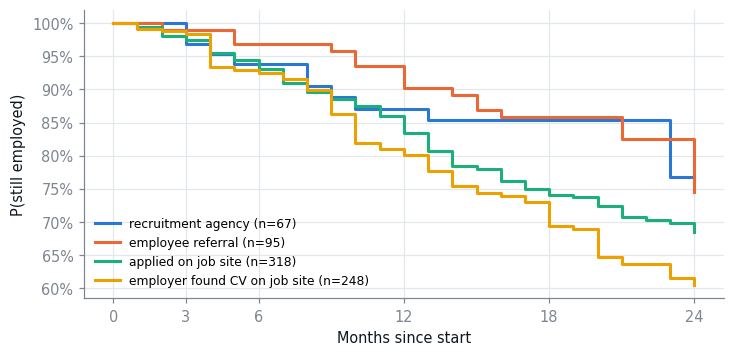

,n_beyond,auc,brier,predicted,observed
6,303,0.586,0.045,0.06,0.046
12,249,0.626,0.129,0.127,0.157
18,204,0.651,0.171,0.209,0.238
24,166,0.636,0.206,0.282,0.309


In [13]:
bab = replay.load_babushkin()
R["babushkin"] = {"channels": {replay.CHANNELS[ch]: {"n": len(g), "curve": [round(replay.km(g.duration, g.cause, t), 4)
                                                                        for t in range(25)]}
                               for ch, g in bab.groupby("traffic")},
                  "order": list(replay.CHANNELS.values())}
test_b = bab.sample(frac=0.3, random_state=1)
rb = pp.HazardModel(replay.BAB_CATS, replay.BAB_NUMS).fit(bab.drop(test_b.index)).risk(test_b)
R["babushkin"]["holdout"] = {str(t): pp.evaluate(test_b.duration, test_b.cause, rb[:, t - 1], t) for t in pp.HORIZONS}
R["babushkin"]["n"] = len(bab)

fig, ax = plt.subplots()
for i, name in enumerate(R["babushkin"]["order"][:4]):
    v = R["babushkin"]["channels"][name]
    ax.step(range(25), v["curve"], where="post", color=S[i], label=f"{name} (n={v['n']})")
ax.set(xlabel="Months since start", ylabel="P(still employed)", xticks=[0, 3, 6, 12, 18, 24])
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.legend(fontsize=8)
plt.show()
pd.DataFrame(R["babushkin"]["holdout"]).T[["n_beyond", "auc", "brier", "predicted", "observed"]]

In [14]:
hue, w = replay.load_huebner()
cut_h = pd.Timestamp("2013-01-01")
tr_h, te_h = hue[hue.start_date < cut_h], hue[hue.start_date >= cut_h]
naive_h = pp.HazardModel(replay.HUE_CATS, replay.HUE_NUMS).fit(tr_h.drop(columns="entry")).risk(te_h)
clean_h = pp.HazardModel(replay.HUE_CATS, replay.HUE_NUMS).fit(tr_h).risk(te_h)
leaky_h = pp.HazardModel(replay.HUE_CATS, replay.HUE_NUMS + replay.HUE_LEAKY).fit(tr_h).risk(te_h)
rows = {}
for t in pp.HORIZONS:
    a, b = (pp.evaluate(te_h.duration, te_h.cause, r[:, t - 1], t) for r in (naive_h, clean_h))
    rows[str(t)] = {"naive": a["predicted"], "corrected": b["predicted"], "observed": b["observed"]}
R["huebner"] = {
    "first_hire": f"{w['first_hire']:%Y}", "window": f"{w['window']:%b %Y}", "n": len(hue), "n_test": len(te_h),
    "quits": int((hue.cause == 1).sum()), "dismissals": int((hue.cause == 2).sum()), "horizons": rows,
    "leak_auc": {"clean": pp.evaluate(te_h.duration, te_h.cause, clean_h[:, 11], 12)["auc"],
                 "leaky": pp.evaluate(te_h.duration, te_h.cause, leaky_h[:, 11], 12)["auc"]},
}
pd.DataFrame(rows).T

,naive,corrected,observed
6,0.007,0.016,0.020
12,0.009,0.018,0.040
18,0.020,0.031,0.066
24,0.025,0.037,0.066


## 9. Write the dashboard

Injects `R` into the `<script id="data">` block of [dashboard.html](dashboard.html). Open that file in a browser, or publish it.

In [12]:
R["checks"] = [
    {"name": "Curves never contradict", "detail": "P(still there) only falls from 6 to 24 months, for every placement"},
    {"name": "Recovers the truth", "detail": "within 2 points at 6, 12, 18 and 24 months despite censoring"},
    {"name": "Check-ins add signal", "detail": f"12-month AUC {lift['12']['static']} to {lift['12']['checkins']}"},
]


def clean(o):
    if isinstance(o, dict):
        return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [clean(v) for v in o]
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (float, np.floating)):
        return None if np.isnan(o) else round(float(o), 4)
    return o


payload = json.dumps(clean(R), separators=(",", ":")).replace("</", "<\\/")
path = Path("dashboard.html")
html = re.sub(r'(<script id="data" type="application/json">).*?(</script>)',
              lambda m: m.group(1) + payload + m.group(2), path.read_text(encoding="utf-8"), flags=re.S)
path.write_text(html, encoding="utf-8")
print(f"dashboard.html updated with {len(payload) / 1024:.0f} KB of results")

dashboard.html updated with 126 KB of results
